# CSC 4110 Machine Learning: task notebook


| Field | Fill in |
|---|---|
| Task | 8 Neural Networks |
| Owner (name) | Collins Kipkorir |
| Registration number | COM/0021/23 |
| Group | G04 |
| Dataset | Credit Risk Dataset |
| Date started | 26 November 2026 |


**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [1]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G04"        # your group, two digits
UNIT = "8"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Mounted at /content/drive
Working in /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04


In [2]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [3]:

# Task 8: Load the Credit Risk Dataset

import os
import pandas as pd
import numpy as np

# Set the correct dataset filename
DATA_FILE = "data/clean_credit.csv"

# Confirm the dataset exists
if not os.path.isfile(DATA_FILE):
    raise FileNotFoundError(
        "Cannot find clean_credit.csv in the G04 data folder."
    )

# Load the dataset
df = pd.read_csv(DATA_FILE)

# Display dataset information
print("Dataset shape:", df.shape)

# Display the first five records
display(df.head())

# Display loan default counts
print("\nLoan default counts:")
print(df["loan_status"].value_counts())

# Count originally observed interest rates
print("\nObserved interest rates:",
      (df["rate_imputed"] == 0).sum())

print("\nTask 8 dataset loaded successfully!")


Dataset shape: (32409, 25)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,age_band,log_income
0,21,9600,OWN,5.0,EDUCATION,1,1000,11.14,0,0.10,...,1,0,0,1,0,0,0,0,under 25,9.169518
1,25,9600,MORTGAGE,1.0,MEDICAL,2,5500,12.87,1,0.57,...,0,0,0,0,0,1,0,0,25-34,9.169518
2,23,65500,RENT,4.0,MEDICAL,2,35000,15.23,1,0.53,...,0,1,0,0,0,1,0,0,under 25,11.089805
3,24,54400,RENT,8.0,MEDICAL,2,35000,14.27,1,0.55,...,0,1,0,0,0,1,0,0,under 25,10.904119
4,21,9900,OWN,2.0,VENTURE,0,2500,7.14,1,0.25,...,1,0,0,0,0,0,0,1,under 25,9.200290



Loan default counts:
loan_status
0    25321
1     7088
Name: count, dtype: int64

Observed interest rates: 29315

Task 8 dataset loaded successfully!



## Task 8(a): Single Perceptron Using NumPy

In this section, I implement a single perceptron using NumPy, including weights, bias, a step activation function and a learning rule.

I train the perceptron on the AND truth table and then test whether a single perceptron can learn the XOR truth table.


In [4]:

# Task 8(a): Implement a perceptron using NumPy

import numpy as np

# Create the AND truth table
X_and = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y_and = np.array([0, 0, 0, 1])

# Define the step activation function
def step_activation(value):
    return int(value >= 0)

# Define the perceptron training function
def train_perceptron(X, y, epochs=100, learning_rate=0.1):

    # Start with zero weights and bias
    weights = np.zeros(X.shape[1])
    bias = 0.0

    # Train the perceptron
    for epoch in range(epochs):

        errors = 0

        for inputs, target in zip(X, y):

            # Calculate the weighted sum
            weighted_sum = np.dot(inputs, weights) + bias

            # Apply the step activation
            prediction = step_activation(weighted_sum)

            # Calculate the learning update
            update = learning_rate * (target - prediction)

            # Update weights and bias
            weights += update * inputs
            bias += update

            if prediction != target:
                errors += 1

        # Stop when all examples are correct
        if errors == 0:
            break

    return weights, bias, epoch + 1

# Train on the AND truth table
w_and, b_and, epochs_and = train_perceptron(
    X_and, y_and
)

# Test the trained perceptron
and_predictions = np.array([
    step_activation(np.dot(x, w_and) + b_and)
    for x in X_and
])

# Display results
print("PERCEPTRON AND RESULTS")
print("Final weights:", w_and)
print("Final bias:", b_and)
print("Epochs trained:", epochs_and)

print("\nAND TRUTH TABLE")
for x, actual, predicted in zip(
    X_and, y_and, and_predictions
):
    print(
        f"{x.astype(int)} | "
        f"Expected: {actual} | Predicted: {predicted}"
    )

# Verify the AND predictions
assert np.array_equal(and_predictions, y_and)

print("\nSUCCESS: Perceptron learned AND!")


PERCEPTRON AND RESULTS
Final weights: [0.2 0.1]
Final bias: -0.20000000000000004
Epochs trained: 4

AND TRUTH TABLE
[0 0] | Expected: 0 | Predicted: 0
[0 1] | Expected: 0 | Predicted: 0
[1 0] | Expected: 0 | Predicted: 0
[1 1] | Expected: 1 | Predicted: 1

SUCCESS: Perceptron learned AND!


In [5]:

# Task 8(a): Test a single perceptron on XOR

# Define the XOR truth table
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y_xor = np.array([0, 1, 1, 0])

# Train a new perceptron on XOR
w_xor, b_xor, epochs_xor = train_perceptron(
    X_xor,
    y_xor,
    epochs=100
)

# Make XOR predictions
xor_predictions = np.array([
    step_activation(np.dot(x, w_xor) + b_xor)
    for x in X_xor
])

# Calculate accuracy
xor_accuracy = np.mean(
    xor_predictions == y_xor
)

# Display results
print("PERCEPTRON XOR RESULTS")
print("Final weights:", w_xor)
print("Final bias:", b_xor)

print("\nXOR TRUTH TABLE")

for x, actual, predicted in zip(
    X_xor, y_xor, xor_predictions
):
    print(
        f"{x.astype(int)} | "
        f"Expected: {actual} | Predicted: {predicted}"
    )

print("\nXOR accuracy:", round(xor_accuracy * 100, 2), "%")

print("\nA single perceptron cannot learn XOR perfectly.")


PERCEPTRON XOR RESULTS
Final weights: [-0.1  0. ]
Final bias: 0.0

XOR TRUTH TABLE
[0 0] | Expected: 0 | Predicted: 1
[0 1] | Expected: 1 | Predicted: 1
[1 0] | Expected: 1 | Predicted: 0
[1 1] | Expected: 0 | Predicted: 0

XOR accuracy: 50.0 %

A single perceptron cannot learn XOR perfectly.



### Task 8(a): Exam Skill — Why a Single Perceptron Fails on XOR

A perceptron is a simple artificial neuron that uses weights, a bias and an activation function to produce a prediction.

My perceptron successfully learned the AND truth table because AND is linearly separable.

However, a single perceptron cannot learn XOR perfectly because XOR is not linearly separable. No single straight-line decision boundary can correctly separate its positive and negative examples.

A multilayer neural network with hidden neurons and nonlinear activation functions can learn XOR because it can create more complex decision boundaries.



## Task 8(b): Multilayer Perceptron Classification

In this section, I train three MLPClassifier architectures to predict loan defaults.

I use scaled numerical features, compare accuracy and F1-score, and select the best architecture using validation data.


In [6]:

# Task 8(b): Prepare classification data

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set the classification target
y = df["loan_status"].astype(int)

# Select numerical features and remove unwanted columns
X = df.select_dtypes(include="number").drop(
    columns=[
        "loan_status",
        "loan_int_rate",
        "rate_imputed"
    ]
)

# Create an 80/20 training and testing split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Create a validation set from the training data
X_fit_raw, X_val_raw, y_fit, y_val = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Fit the scaler using model-training records only
scaler = StandardScaler()

X_fit = scaler.fit_transform(X_fit_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

# Display results
print("NEURAL NETWORK DATA PREPARATION")

print("Model-training records:", len(X_fit))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))
print("Input features:", X_fit.shape[1])

print("\nData prepared successfully!")


NEURAL NETWORK DATA PREPARATION
Model-training records: 20741
Validation records: 5186
Testing records: 6482
Input features: 19

Data prepared successfully!


In [7]:

# Task 8(b): Train and compare three neural networks

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

# Define the three required architectures
architectures = {
    "16": (16,),
    "32-16": (32, 16),
    "64-32-16": (64, 32, 16)
}

# Store models and their results
mlp_models = {}
mlp_rows = []

# Train each architecture
for name, layers in architectures.items():

    print(f"\nTraining MLP {name}...")

    # Create the neural network
    model = MLPClassifier(
        hidden_layer_sizes=layers,
        activation="relu",
        solver="adam",
        max_iter=300,
        random_state=42,
        early_stopping=False
    )

    # Train the model
    model.fit(X_fit, y_fit)

    # Predict validation and test records
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    # Save the trained model
    mlp_models[name] = model

    # Store evaluation results
    mlp_rows.append({
        "Architecture": name,
        "Validation F1": f1_score(y_val, val_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test F1": f1_score(y_test, test_pred)
    })

    print(f"Finished MLP {name}")

# Create the required results variable
mlp_results = pd.DataFrame(
    mlp_rows
).set_index("Architecture")

print("\nNEURAL NETWORK COMPARISON")
display(mlp_results.round(4))

# Select the best architecture using validation F1
best_architecture = mlp_results["Validation F1"].idxmax()

# Store the best trained neural network
best_mlp = mlp_models[best_architecture]

print("\nBest architecture:", best_architecture)
print("Best validation F1:",
      round(mlp_results.loc[
          best_architecture, "Validation F1"
      ], 4))

print("\nMLP training completed successfully!")



Training MLP 16...
Finished MLP 16

Training MLP 32-16...
Finished MLP 32-16

Training MLP 64-32-16...
Finished MLP 64-32-16

NEURAL NETWORK COMPARISON


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,Validation F1,Test Accuracy,Test F1
Architecture,,,
16,0.7696,0.9175,0.7869
32-16,0.7751,0.9209,0.7941
64-32-16,0.7579,0.9081,0.7709



Best architecture: 32-16
Best validation F1: 0.7751

MLP training completed successfully!


Best architecture: 32-16
Training iterations: 211
Final training loss: 0.196886


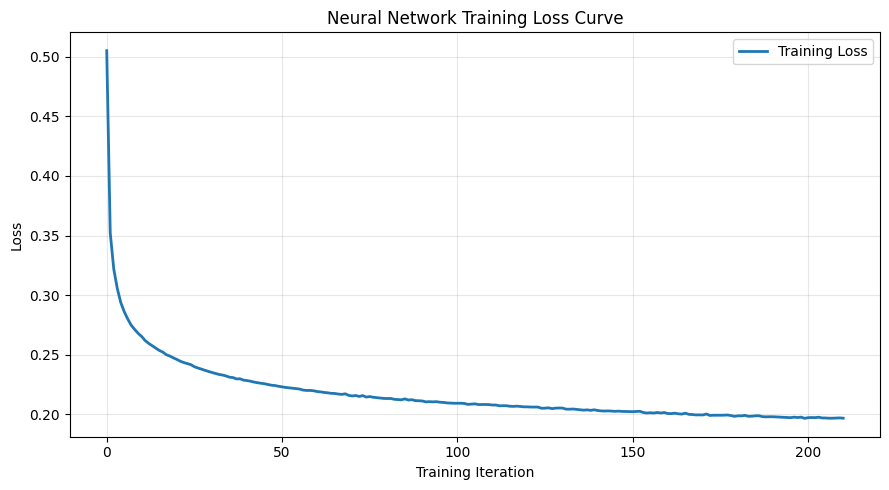

Saved: outputs/loss_curve.png


In [8]:

# Task 8(b): Plot the best neural network's loss curve

# Display the selected architecture
print("Best architecture:", best_architecture)

# Display training information
print("Training iterations:", best_mlp.n_iter_)
print("Final training loss:", round(best_mlp.loss_, 6))

# Create the graph
plt.figure(figsize=(9, 5))

plt.plot(
    best_mlp.loss_curve_,
    linewidth=2,
    label="Training Loss"
)

# Add labels
plt.title("Neural Network Training Loss Curve")
plt.xlabel("Training Iteration")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)

# Save the required graph
plt.tight_layout()
plt.savefig("outputs/loss_curve.png", dpi=150)

# Display the graph
plt.show()

print("Saved: outputs/loss_curve.png")



### Task 8(b): Early Stopping Experiment

This section compares the best neural network architecture with and without early stopping.

Early stopping can help reduce overfitting by stopping training when validation performance stops improving.


In [9]:

# Task 8(b): Compare MLP with and without early stopping

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

# Create an MLP with the selected architecture
mlp_early = MLPClassifier(
    hidden_layer_sizes=architectures[best_architecture],
    activation="relu",
    solver="adam",
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

# Train using the same model-training records
mlp_early.fit(X_fit, y_fit)

# Evaluate both models on the held-out validation set
pred_without = best_mlp.predict(X_val)
pred_with = mlp_early.predict(X_val)

# Create comparison results
early_results = pd.DataFrame({
    "Model": [
        "Without Early Stopping",
        "With Early Stopping"
    ],
    "Validation Accuracy": [
        accuracy_score(y_val, pred_without),
        accuracy_score(y_val, pred_with)
    ],
    "Validation F1": [
        f1_score(y_val, pred_without),
        f1_score(y_val, pred_with)
    ],
    "Iterations": [
        best_mlp.n_iter_,
        mlp_early.n_iter_
    ]
})

# Display comparison
print("EARLY STOPPING COMPARISON")
display(early_results.round(4))

# Show whether the F1-score changed
f1_difference = (
    f1_score(y_val, pred_with)
    - f1_score(y_val, pred_without)
)

print("\nChange in validation F1:",
      round(f1_difference, 4))

print("Early stopping experiment completed!")


EARLY STOPPING COMPARISON


,Model,Validation Accuracy,Validation F1,Iterations
0,Without Early Stopping,0.9150,0.7751,211
1,With Early Stopping,0.9142,0.7712,90



Change in validation F1: -0.0039
Early stopping experiment completed!



## Task 8(c): Comparing Activation Functions

In this section, I compare ReLU, tanh and logistic activation functions using the selected (32, 16) neural network architecture.

I use validation accuracy and F1-score to evaluate their performance.


In [10]:

# Task 8(c): Compare three neural network activation functions

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

# Define the required activation functions
activations = ["relu", "tanh", "logistic"]

# Store the results and trained models
activation_rows = []
activation_models = {}

# Train using the best architecture
for activation in activations:

    print(f"Training with {activation} activation...")

    # Create the neural network
    model = MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation=activation,
        solver="adam",
        max_iter=300,
        random_state=42
    )

    # Train the network
    model.fit(X_fit, y_fit)

    # Predict on validation data
    predictions = model.predict(X_val)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_val, predictions)
    f1 = f1_score(y_val, predictions)

    # Store the trained model
    activation_models[activation] = model

    # Store the results
    activation_rows.append({
        "Activation": activation,
        "Validation Accuracy": accuracy,
        "Validation F1": f1,
        "Iterations": model.n_iter_
    })

# Create the required results variable
activation_results = pd.DataFrame(activation_rows)

# Display results
print("\nACTIVATION FUNCTION COMPARISON")
display(activation_results.round(4))

# Identify the best activation by validation F1
best_activation = activation_results.loc[
    activation_results["Validation F1"].idxmax(),
    "Activation"
]

print("\nBest activation:", best_activation)
print("\nActivation comparison completed successfully!")


Training with relu activation...
Training with tanh activation...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Training with logistic activation...

ACTIVATION FUNCTION COMPARISON


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,Activation,Validation Accuracy,Validation F1,Iterations
0,relu,0.9150,0.7751,211
1,tanh,0.9134,0.7745,300
2,logistic,0.9117,0.7682,300



Best activation: relu

Activation comparison completed successfully!



### Task 8(c): Exam Skill — Activation Functions

An activation function introduces nonlinearity into a neural network, allowing it to learn complex relationships that cannot be represented by a simple straight-line model.

ReLU outputs zero for negative inputs and positive values unchanged. Tanh produces values between -1 and 1, while logistic activation produces values between 0 and 1.

The hidden layers use activation functions to learn patterns in borrower characteristics.

For binary classification, the output layer uses a sigmoid function to produce a probability of loan default. For regression, the output layer generally uses a linear activation because the predicted interest rate is a continuous numerical value.

The three activation functions were compared using validation F1-score to determine which performed best.

I compared ReLU, tanh and logistic activation functions using the (32, 16) neural network architecture.

ReLU achieved the highest validation F1-score of 0.7751, followed by tanh at 0.7745 and logistic at 0.7682.

An activation function introduces nonlinearity, allowing neural networks to learn complex relationships between borrower characteristics.

ReLU returns zero for negative inputs and positive inputs unchanged. Tanh produces values between -1 and 1, while logistic activation produces values between 0 and 1.

For binary classification, the output layer uses a sigmoid function to estimate default probability. For regression, a linear output is appropriate because the predicted interest rate is continuous.



## Task 8(d): MLP Regression for Loan Interest Rates

In this section, I train an MLPRegressor to predict annual loan interest rates.

I exclude records whose interest rates were imputed, remove leakage-related features and fit the scaler using training records only.

I compare the neural network's test RMSE with the regression models from Task 3.2.


In [11]:

# Task 8(d): Train an MLPRegressor for interest rates

from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# Use only originally observed interest rates
reg_data = df[df["rate_imputed"] == 0].copy()

# Set the regression target
y_reg = reg_data["loan_int_rate"]

# Select numerical features
# Remove the interest-rate target and leakage columns
X_reg = reg_data.select_dtypes(include="number").drop(
    columns=[
        "loan_int_rate",
        "loan_grade",
        "loan_status",
        "rate_imputed"
    ]
)

# Split into training and testing data
X_reg_train, X_reg_test, y_reg_train, y_reg_test = (
    train_test_split(
        X_reg,
        y_reg,
        test_size=0.20,
        random_state=42
    )
)

# Fit the scaler on training data only
reg_scaler = StandardScaler()

X_reg_train_scaled = reg_scaler.fit_transform(
    X_reg_train
)

X_reg_test_scaled = reg_scaler.transform(
    X_reg_test
)

# Create the regression neural network
mlp_reg = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=300,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=42
)

# Train the regression network
mlp_reg.fit(
    X_reg_train_scaled,
    y_reg_train
)

# Predict interest rates
reg_predictions = mlp_reg.predict(
    X_reg_test_scaled
)

# Calculate the required test RMSE
mlp_reg_rmse = float(
    np.sqrt(
        mean_squared_error(
            y_reg_test,
            reg_predictions
        )
    )
)

# Display results
print("MLP REGRESSION RESULTS")
print("Training records:", len(X_reg_train))
print("Testing records:", len(X_reg_test))
print("Input features:", X_reg.shape[1])

print("\nMLP Regression Test RMSE:",
      round(mlp_reg_rmse, 4))

# Compare with previous multiple linear regression
baseline_rmse = 2.7171

print("\nTask 3.2 Regression RMSE:",
      baseline_rmse)

print("MLP RMSE:", round(mlp_reg_rmse, 4))

print("\nMLP has lower RMSE:",
      mlp_reg_rmse < baseline_rmse)

print("\nMLP Regression completed successfully!")


MLP REGRESSION RESULTS
Training records: 23452
Testing records: 5863
Input features: 18

MLP Regression Test RMSE: 2.7181

Task 3.2 Regression RMSE: 2.7171
MLP RMSE: 2.7181

MLP has lower RMSE: False

MLP Regression completed successfully!


## Part a) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# a1. <what this cell does>


## Part b) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# b1. <what this cell does>


## Part c) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# c1. <what this cell does>


## Written answer


## Task 8: Written Answer — Neural Networks

I implemented a single perceptron using NumPy and trained it on the AND truth table. The perceptron achieved 100% accuracy on AND but only 50% on XOR because XOR is not linearly separable.

For loan-default classification, I compared three multilayer perceptron architectures: (16,), (32, 16) and (64, 32, 16).

The (32, 16) architecture performed best based on validation F1-score, achieving 0.7751. Its test accuracy was 92.09% and test F1-score was 0.7941.

I compared ReLU, tanh and logistic activation functions. ReLU performed best with a validation F1-score of 0.7751.

Early stopping reduced training iterations from 211 to 90, but validation F1 decreased slightly from 0.7751 to 0.7712.

For interest-rate prediction, the MLPRegressor achieved a test RMSE of 2.7181, compared with 2.7171 for the earlier multiple linear regression model. Therefore, the neural network did not improve regression performance in this experiment.

The best Random Forest from Task 6 achieved a classification F1-score of 0.8333, compared with 0.7941 for my best MLP. The Random Forest performed better in these reported results, although the models used different training-set sizes.

A simpler model may still be preferable because it can be easier to interpret, maintain and explain to loan officers.

Overall, neural networks can learn complex relationships, but increasing model complexity does not guarantee better predictions.


## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [12]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 8
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [ ]:
# Paste the self-check cell from Moodle here
